In [1]:
import keras.models

print('Facial Recognition System')

Facial Recognition System


In [2]:
import tensorflow as tf

In [3]:
!pip list

Package                   Version
------------------------- --------------
absl-py                   2.3.1
aiohappyeyeballs          2.6.1
aiohttp                   3.12.15
aiosignal                 1.4.0
albucore                  0.0.24
albumentations            2.0.8
annotated-types           0.7.0
anyio                     4.9.0
argon2-cffi               25.1.0
argon2-cffi-bindings      21.2.0
arrow                     1.3.0
asttokens                 3.0.0
astunparse                1.6.3
async-lru                 2.0.5
attrs                     25.3.0
babel                     2.17.0
beautifulsoup4            4.13.4
bleach                    6.2.0
certifi                   2025.6.15
cffi                      1.17.1
charset-normalizer        3.4.2
click                     8.2.1
colorama                  0.4.6
coloredlogs               15.0.1
comm                      0.2.2
contourpy                 1.3.3
cycler                    0.12.1
debugpy                   1.8.14
decorator    

In [4]:
# Importing standard dependencies
import cv2
import matplotlib.pyplot as plt
import os
import random
import numpy as np

In [5]:
# Importing tensorflow dependencies
from keras.models import Model
from keras.layers import Conv2D,Flatten,Dense,Layer,MaxPooling2D,Input


In [6]:
gpus = tf.config.experimental.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print(e)

In [7]:
print(len(gpus))
for gpu in gpus:
    print(gpu)

2
PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')
PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')


# Crete folder structures

In [8]:
posPath=os.path.join('data','positive')
negPath=os.path.join('data','negative')
ancPath=os.path.join('data','anchor')

In [15]:
# making directories
directory = [posPath,negPath,ancPath]
for i in directory:
    os.makedirs(i)

In [11]:
for directory in os.listdir('archive'):
    for file in os.listdir(os.path.join('archive',directory)):
        exPath = os.path.join('archive',directory,file)
        newPath = os.path.join(negPath,file)
        os.replace(exPath,newPath)



# collect positive and anchor classes

In [9]:
import uuid

In [21]:
# establishing a connection to the webcam
cap = cv2.VideoCapture(0)
while cap.isOpened():
    ret,frame = cap.read()

    # cut down frame to 250x250x
    frame = frame[120:120+250,200:200+250,:]

    # collect anchor
    if cv2.waitKey(1) & 0XFF ==ord('a'):
        # create the unique file path
        imgName = os.path.join(ancPath,'{}.jpg'.format(uuid.uuid1()))
        #write out anchor image
        cv2.imwrite(imgName,frame)

    # collect positive
    if cv2.waitKey(1) & 0XFF ==ord('p'):
        # create the unique file path
        imgName = os.path.join(posPath,'{}.jpg'.format(uuid.uuid1()))
        #write out anchor image
        cv2.imwrite(imgName,frame)

    # show image back to the screen
    cv2.imshow('imageCollection',frame)

    # breaking the camera connection
    if cv2.waitKey(1) & 0XFF ==ord('q'):
        break
cap.release()
cv2.destroyAllWindows()

# Load and preprocess images

In [10]:
# Get image directories
anchor = tf.data.Dataset.list_files(ancPath+'\*.jpg').take(330)
positive = tf.data.Dataset.list_files(posPath+'\*.jpg').take(330)
negative = tf.data.Dataset.list_files(negPath+'\*.jpg').take(330)

In [11]:
dirTest = anchor.as_numpy_iterator()

In [12]:
dirTest.next()

b'data\\anchor\\615c528d-a001-11f0-8a75-50c2e80c162a.jpg'

In [13]:
# preprocessing - Scale and Resize

def preprocess(filePath):
    # read in image from  file path
    byteImg = tf.io.read_file(filePath)
    # load in the image
    img = tf.io.decode_jpeg(byteImg)
    # preprocessing steps - resizing the image to be 100x100x3
    img = tf.image.resize(img,(100,100))
    #scale image to be between 0 and 1
    img  =img/255.0
    return img

In [14]:
img  =preprocess('data\\anchor\\77b8ef46-a001-11f0-a248-50c2e80c162a.jpg')

In [15]:
# (anchor ,positive) -> 1,1,1,1,1
# (anchor ,negative) -> 0,0,0,0,0

In [16]:
positives  =tf.data.Dataset.zip((anchor,positive,tf.data.Dataset.from_tensor_slices(tf.ones(len(anchor)))))
negatives  =tf.data.Dataset.zip((anchor,negative,tf.data.Dataset.from_tensor_slices(tf.zeros(len(anchor)))))
data=positives.concatenate(negatives)

In [17]:
sample = data.as_numpy_iterator()

In [18]:
example= sample.next()

# build test and train partition

In [19]:
def preprocessTwin(inputImg,validationImg,label):
    return preprocess(inputImg),preprocess(validationImg),label

In [20]:
res = preprocessTwin(*example)

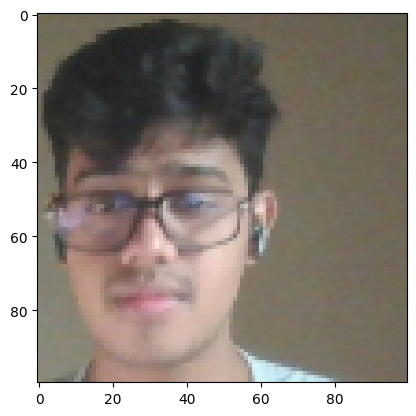

In [21]:
plt.imshow(res[1])

In [22]:
# build dataloader pipeline
data= data.map(preprocessTwin)
data = data.cache()
data=data.shuffle(buffer_size=1024)

In [23]:
#trainig partition
trainData = data.take(round(len(data)*.7))
trainData = trainData.batch(16)
trainData  =trainData.prefetch(8)

In [24]:
trainSamples =trainData.as_numpy_iterator()

In [25]:
trainSample = trainSamples.next()

In [26]:
len(trainSample[0])

16

In [27]:
testData = data.skip(round(len(data)*0.7))
testData = testData.take(round(len(data)*0.3))
testData = trainData.batch(16)
testData  =trainData.prefetch(8)

#  model engineering

In [28]:
# build embedding layer

def makeEmbedding():
    inp = Input(shape=(100,100,3),name='inputImage')

    #first block
    c1 = Conv2D(64,(10,10),activation='relu')(inp)
    m1 = MaxPooling2D(64,(2,2),padding='same')(c1)

    # second block
    c2 = Conv2D(128,(7,7),activation='relu')(m1)
    m2 = MaxPooling2D(64,(2,2),padding='same')(c2)

    #third block
    c3 = Conv2D(128,(4,4),activation='relu')(m2)
    m3 = MaxPooling2D(64,(2,2),padding='same')(c3)

    #final embedding block
    c4 = Conv2D(256,(4,4),activation='relu')(m3)
    f1 = Flatten()(c4)
    d1 = Dense(4096,activation='sigmoid')(f1)


    return Model(inputs=[inp],outputs=[d1],name='embedding')

In [29]:
embedding = makeEmbedding()

In [30]:
embedding.summary()

Model: "embedding"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 inputImage (InputLayer)     [(None, 100, 100, 3)]     0         
                                                                 
 conv2d (Conv2D)             (None, 91, 91, 64)        19264     
                                                                 
 max_pooling2d (MaxPooling2D  (None, 46, 46, 64)       0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 40, 40, 128)       401536    
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 20, 20, 128)      0         
 2D)                                                             
                                                                 
 conv2d_2 (Conv2D)           (None, 17, 17, 128)       26

In [31]:
# build distance layers
class L1Dist(Layer):
    def __init__(self, **kwargs):
        super().__init__()
    def call(self,inputEmbedding,validationEmbedding):
        return tf.math.abs(inputEmbedding-validationEmbedding)

In [32]:
l1=L1Dist()

In [33]:
# make siamese model
def makeSiameseModel():

    # anchor image input in the network
    inputImage = Input(name='inputImg',shape=(100,100,3))

    # validation image in the network
    validationImage = Input(name='validationImg',shape=(100,100,3))

    # Combine siamese distance components
    siameseLayer = L1Dist()
    siameseLayer._name = 'distance'
    distances = siameseLayer(embedding(inputImage),embedding(validationImage))

    # Classification layer
    classifier = Dense(1,activation='sigmoid')(distances)
    return Model(inputs=[inputImage,validationImage],outputs=classifier,name='Siamese_Network')


In [34]:
siameseModel = makeSiameseModel()

In [35]:
siameseModel.summary()

Model: "Siamese_Network"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 inputImg (InputLayer)          [(None, 100, 100, 3  0           []                               
                                )]                                                                
                                                                                                  
 validationImg (InputLayer)     [(None, 100, 100, 3  0           []                               
                                )]                                                                
                                                                                                  
 embedding (Functional)         (None, 4096)         38960448    ['inputImg[0][0]',               
                                                                  'validationImg[0][

# Training

In [36]:
# setup loss and optimizer
binaryCrossLoss = tf.losses.binary_crossentropy

In [37]:
opt = tf.keras.optimizers.Adam(1e-4)

In [38]:
# establish checkpoints
checkpointDir = './trainingCheckpoints'
checkpointPrefix = os.path.join(checkpointDir,'ckpt')
checkpoint = tf.train.Checkpoint(opt=opt,siamese_model = siameseModel)

In [39]:
# build train step function
@tf.function
def trainStep(batch):
    with tf.GradientTape() as tape:
        # get anchor and positive/negative images
        x = batch[:2]
        # get label
        y = batch[2]
        y = tf.reshape(y, (-1, 1))  # Fix label shape here

        # forward pass
        yhat = siameseModel(x,training=True)
        # calculate loss
        loss = binaryCrossLoss(y,yhat)
    print(loss)
    # calculate gradients

    grad = tape.gradient(loss,siameseModel.trainable_variables)

    # calculate updated weights and apply to a siamese model
    opt.apply_gradients(zip(grad,siameseModel.trainable_variables))

    return loss

In [40]:
# building training loop

def train(data,epochs):
    # loop through epochs
    for epoch in range(1,epochs+1):
        print('\n Epoch {}/{}'.format(epoch,epochs))
        progbar = tf.keras.utils.Progbar(len(data))

        # loop through each batch
        for idx,batch in enumerate(data):
            # run train step here
            trainStep(batch)
            progbar.update(idx+1)

        # save checkpoints
        if epoch %10 ==0:
            checkpoint.save(file_prefix = checkpointPrefix)




In [41]:
# train the model

epochs=50

train(trainData,epochs)




 Epoch 1/50
Tensor("Mean:0", shape=(16,), dtype=float32)
Tensor("Mean:0", shape=(16,), dtype=float32)
29/29 [==============================] - 15s 508ms/step

 Epoch 2/50
29/29 [==============================] - 14s 465ms/step

 Epoch 3/50
29/29 [==============================] - 14s 459ms/step

 Epoch 4/50
29/29 [==============================] - 14s 469ms/step

 Epoch 5/50
29/29 [==============================] - 15s 495ms/step

 Epoch 6/50
29/29 [==============================] - 14s 482ms/step

 Epoch 7/50
29/29 [==============================] - 15s 495ms/step

 Epoch 8/50
29/29 [==============================] - 15s 509ms/step

 Epoch 9/50
29/29 [==============================] - 14s 503ms/step

 Epoch 10/50
29/29 [==============================] - 15s 506ms/step

 Epoch 11/50
29/29 [==============================] - 14s 479ms/step

 Epoch 12/50
29/29 [==============================] - 15s 492ms/step

 Epoch 13/50
29/29 [==============================] - 14s 509ms/step

 Epoch 1

# Evaluate model

In [42]:
# import metric calculations
from keras.metrics import Precision,Recall


In [58]:
# get a batch of test data
testInput,testVal,yTrue = testData.as_numpy_iterator().next()


In [59]:
testInput

array([[[[0.45514706, 0.41593137, 0.3767157 ],
         [0.45171568, 0.4134804 , 0.3752451 ],
         [0.4497549 , 0.41446078, 0.37916666],
         ...,
         [0.40269607, 0.36372548, 0.33063725],
         [0.38627452, 0.35759804, 0.31789216],
         [0.37745097, 0.35392156, 0.30686274]],

        [[0.4480392 , 0.41862744, 0.3647059 ],
         [0.44117647, 0.4107843 , 0.35686275],
         [0.45171568, 0.41887254, 0.3745098 ],
         ...,
         [0.4004902 , 0.37107843, 0.31715685],
         [0.39289215, 0.36789215, 0.31176472],
         [0.3872549 , 0.36397058, 0.30490196]],

        [[0.44240198, 0.42181373, 0.3502451 ],
         [0.45637256, 0.42745098, 0.35955882],
         [0.46078432, 0.41936275, 0.35661766],
         ...,
         [0.4       , 0.3852941 , 0.3137255 ],
         [0.3872549 , 0.3732843 , 0.2995098 ],
         [0.38137254, 0.36764705, 0.29313725]],

        ...,

        [[0.4884804 , 0.41446078, 0.37696078],
         [0.5247549 , 0.42181373, 0.3875    ]

In [60]:
testVal

array([[[[0.00000000e+00, 4.65686293e-03, 9.80392192e-03],
         [2.00980399e-02, 1.91176478e-02, 2.96568628e-02],
         [3.84803936e-02, 1.76470596e-02, 2.81862747e-02],
         ...,
         [0.00000000e+00, 7.35294132e-04, 1.78921577e-02],
         [7.35294132e-04, 2.45098054e-04, 1.47058826e-03],
         [3.92156886e-03, 0.00000000e+00, 0.00000000e+00]],

        [[4.16666688e-03, 1.20098041e-02, 0.00000000e+00],
         [1.50980398e-01, 1.46323532e-01, 1.10294119e-01],
         [5.47303915e-01, 5.20833313e-01, 4.74754900e-01],
         ...,
         [5.98039217e-02, 7.35294148e-02, 1.20098040e-01],
         [2.42647063e-02, 2.20588241e-02, 4.50980403e-02],
         [2.94117653e-03, 0.00000000e+00, 1.47058826e-03]],

        [[1.05392160e-02, 1.71568629e-03, 0.00000000e+00],
         [2.85784304e-01, 2.67401963e-01, 2.16421574e-01],
         [6.83088243e-01, 6.40931368e-01, 5.59313715e-01],
         ...,
         [5.17156869e-02, 6.64215684e-02, 1.55882359e-01],
         [

In [61]:
yTrue

array([0., 0., 0., 0., 0., 0., 0., 1., 1., 0., 1., 0., 1., 0., 1., 0.],
      dtype=float32)

In [62]:
#make predictions
yhat = siameseModel.predict([testInput,testVal])

1/1 [==============================] - 0s 30ms/step


In [63]:
yhat

array([[5.1199081e-09],
       [9.5493760e-07],
       [2.9446141e-05],
       [6.6225944e-08],
       [3.2208222e-06],
       [9.6199400e-08],
       [1.0877178e-06],
       [1.0000000e+00],
       [9.9864465e-01],
       [1.7793221e-07],
       [1.0000000e+00],
       [1.9679994e-06],
       [1.0000000e+00],
       [6.5947923e-08],
       [1.0000000e+00],
       [7.9842799e-08]], dtype=float32)

In [64]:
# post-processing the result
[1 if prediction>0.5 else 0 for prediction in yhat]


[0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0]

In [65]:
yTrue

array([0., 0., 0., 0., 0., 0., 0., 1., 1., 0., 1., 0., 1., 0., 1., 0.],
      dtype=float32)

In [51]:
# creating a metric object
m=Recall()

# calculating the recall value
m.update_state(yTrue,yhat)

# return recall result
m.result().numpy()

0.99999994

In [52]:
# creating a metric object
m=Precision()

# calculating the recall value
m.update_state(yTrue,yhat)

# return recall result
m.result().numpy()

0.99999994

# visualize result

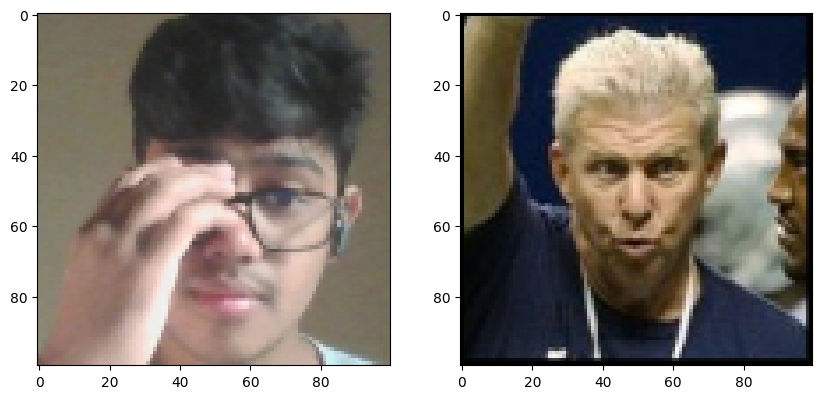

In [66]:
# set plot size
plt.figure(figsize=(10,8))

# set first subplot
plt.subplot(1,2,1)
plt.imshow(testInput[0])

# set second subplot
plt.subplot(1,2,2)
plt.imshow(testVal[0])
plt.show()

# Save model

In [54]:
# save weights

siameseModel.save('siameseModel.h5')

In [69]:
# reload model

model = tf.keras.models.load_model('siameseModel.h5',
                                custom_objects={'L1Dist':L1Dist,
                                               'BinaryCrossEntropy':tf.losses.BinaryCrossentropy})

In [70]:
model.predict([testInput,testVal])

1/1 [==============================] - 0s 98ms/step


array([[5.1199081e-09],
       [9.5493760e-07],
       [2.9446141e-05],
       [6.6225944e-08],
       [3.2208222e-06],
       [9.6199400e-08],
       [1.0877178e-06],
       [1.0000000e+00],
       [9.9864465e-01],
       [1.7793221e-07],
       [1.0000000e+00],
       [1.9679994e-06],
       [1.0000000e+00],
       [6.5947923e-08],
       [1.0000000e+00],
       [7.9842799e-08]], dtype=float32)

In [71]:
model.summary()

Model: "Siamese_Network"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 inputImg (InputLayer)          [(None, 100, 100, 3  0           []                               
                                )]                                                                
                                                                                                  
 validationImg (InputLayer)     [(None, 100, 100, 3  0           []                               
                                )]                                                                
                                                                                                  
 embedding (Functional)         (None, 4096)         38960448    ['inputImg[0][0]',               
                                                                  'validationImg[0][

# real time test

In [83]:
# verification function
def verify(model,detectionThreshold,verificationThreshold):

    # build results array
    results=[]
    for image in os.listdir(os.path.join('applicationData','verificationImages')):
        inputImg = preprocess(os.path.join('applicationData','inputImages','inputImages.jpg'))
        validationImg = preprocess(os.path.join('applicationData','verificationImages',image))

        # make prediction
        result=model.predict(list(np.expand_dims([inputImg,validationImg],axis=1)))
        results.append(result)

    # detectionThreshold -> metrics above which a prediction is considered positive
    detection = np.sum(np.array(results) > detectionThreshold)

#   verificationThreshold -> proportion of positive prediction /total positive samples
    verification = detection/len(os.listdir(os.path.join('applicationData','verificationImages')))
    verified = verification>verificationThreshold

    return results,verified

In [90]:
# establishing a connection to the webcam
cap = cv2.VideoCapture(0)
while cap.isOpened():
    ret,frame = cap.read()

    # cut down frame to 250x250x
    frame = frame[120:120+250,200:200+250,:]
    # show image back to the screen
    cv2.imshow('Verification',frame)

    # verification trigger

    if cv2.waitKey(1) & 0XFF ==ord('v'):
# save input images to the applicationData / inputImage folder
        cv2.imwrite(os.path.join('applicationData','inputImages','inputImages.jpg '),frame)
        # run verification
        results,verified = verify(model,0.9,0.7)
        print(verified)

    # breaking the camera connection
    if cv2.waitKey(1) & 0XFF ==ord('q'):
        break
cap.release()
cv2.destroyAllWindows()

1/1 [==============================] - 0s 15ms/step
True
1/1 [==============================] - 0s 15ms/step
True
1/1 [==============================] - 0s 16ms/step
True
1/1 [==============================] - 0s 14ms/step
True


In [91]:
np.sum(np.squeeze(results)>0.5)

89

In [92]:
! pip list

Package                   Version
------------------------- --------------
absl-py                   2.3.1
aiohappyeyeballs          2.6.1
aiohttp                   3.12.15
aiosignal                 1.4.0
albucore                  0.0.24
albumentations            2.0.8
annotated-types           0.7.0
anyio                     4.9.0
argon2-cffi               25.1.0
argon2-cffi-bindings      21.2.0
arrow                     1.3.0
asttokens                 3.0.0
astunparse                1.6.3
async-lru                 2.0.5
attrs                     25.3.0
babel                     2.17.0
beautifulsoup4            4.13.4
bleach                    6.2.0
certifi                   2025.6.15
cffi                      1.17.1
charset-normalizer        3.4.2
click                     8.2.1
colorama                  0.4.6
coloredlogs               15.0.1
comm                      0.2.2
contourpy                 1.3.3
cycler                    0.12.1
debugpy                   1.8.14
decorator    